# B-IRT / B-MI — Common-item design (`CMCommonItem`)

Bayesian arms for one masked design of the WD-FAB-DE Community Mobility
missing-data comparison. **Generated by `notebooks/make_design_notebooks.py`
— edit the generator, not this file.** All logic lives in `mice_imp/`; this
notebook sets a design, calls in, and plots.

## This design

All six anchors administered in all three forms.

| | |
|---|---|
| form-pair overlap (1&2 / 1&3 / 2&3) | 6 / 6 / 6 |
| items administered per form | 13 / 13 / 12 |
| respondents per form | 455 / 454 / 454 |

| anchor | administered in forms |
|---|---|
| `DA054` | 1, 2, 3 |
| `DA058` | 1, 2, 3 |
| `DA060` | 1, 2, 3 |
| `DA064` | 1, 2, 3 |
| `DA066` | 1, 2, 3 |
| `DA067` | 1, 2, 3 |

The other 20 items sit in exactly one form each, identically across all
three designs.

This is the only design with a common anchor set across all three forms, so it is the one where Stocking-Lord linking and MG-IRT are on their strongest footing. Expect it to be the most favourable design for the frequentist arms -- which is the point of including it.

## The three arms

| arm | imputation | what it is |
|---|---|---|
| `birt` | none | masked cells contribute exactly 0 to the log-likelihood |
| `bmi` | `PairwiseOrdinalStackingModel` PMFs | masked cells contribute `log sum_k q_k p_k(phi)` — analytic Rao-Blackwellisation, **not** Rubin-style MI |
| `flat` | uniform `1/K` | noise-floor control |

`flat` targets **exactly the same posterior** as `birt`: with `q_k = 1/K` the
masked-cell contribution is `log(1/K)`, a constant with zero gradient. Any
`flat`-vs-`birt` difference is Monte Carlo noise, and it tells you the
resolution at which a real B-MI effect could be detected. A *systematic*
difference means the plumbing is wrong.

Run order matters: `bmi` reuses `birt`'s ADVI warm-start.

## Setup

In [1]:
import os
import sys
from pathlib import Path

REPO = Path("/home/luis/CGE/mice_imp")
sys.path.insert(0, str(REPO))

os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("JAX_ENABLE_X64", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mice_imp.wdfab_io import ITEM_KEYS, FORM_KEY, load_cm, describe
from mice_imp.cm_bayes_arms import (
    fit_arm, fit_imputation_model, PairwiseOnlyImputationModel, _report_noise_floor,
)

DESIGN = "CommonItem"
DATA_PATH = REPO / "data_wdfab" / f"WDFAB_ExperimentalData_CM{DESIGN}_Jul2026.dta"
OUTPUT_DIR = REPO / "results" / DESIGN.lower()
IMPUTER_PATH = OUTPUT_DIR / "imputation_model"

CARDINALITY = 5
SEED = 42

# SMOKE = True gives a fast wiring check, NOT an inferential run. Flip to
# False for the real thing. CLAUDE.md: smoke-test before committing to full
# chains -- nothing in this pipeline has been executed end to end.
SMOKE = False

if SMOKE:
    NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 2, 200, 200
else:
    NUM_CHAINS, NUM_WARMUP, NUM_SAMPLES = 4, 3000, 2000

# Chang's defaults. B-MI gets a gentler sampler: attaching PMFs turns masked
# cells from exact zeros into parameter-dependent curvature, which makes the
# geometry harder for NUTS.
STEP_SIZE, TARGET_ACCEPT = 0.002, 0.95
BMI_STEP_SIZE, BMI_TARGET_ACCEPT = 0.0005, 0.98

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"design={DESIGN}  smoke={SMOKE}  chains={NUM_CHAINS} "
      f"warmup={NUM_WARMUP} samples={NUM_SAMPLES}")
print(f"out: {OUTPUT_DIR}")

design=CommonItem  smoke=False  chains=4 warmup=3000 samples=2000
out: /home/luis/CGE/mice_imp/results/commonitem


## Load

`load_cm` reads the `.dta` with `convert_categoricals=False` (the default
returns the German label *strings*) and shifts the raw 1..5 codes onto 0..4,
raising on anything out of range. That shift is not cosmetic: `GRModel` masks
a cell wherever `(y < 0) | (y >= response_cardinality) | isnan(y)`, so a
stored `5` with `response_cardinality=5` would vanish from the likelihood
without an error.

26 items — `Bike_2` is excluded. It is one item stored in two columns
(`Bike_2_r == 6 - Bike_2`), and the design files handed the two columns to
different forms as if they were separate items. See CLAUDE.md fact 16.

In [2]:
df = load_cm(DATA_PATH, cardinality=CARDINALITY)
describe(df, ITEM_KEYS)

fitting_frame = df[ITEM_KEYS]
print(f"\nfitting frame: {fitting_frame.shape[0]} x {fitting_frame.shape[1]}")

N = 1363   items = 26   missing = 55.0%   complete rows = 0

administered items by grp_final (x = administered, . = masked by design):
  form  1.0  n=  455  .xx.xx..xxxxxx..x......x.x  (13 items)
  form  2.0  n=  454  x.xxxxxx.xxx.......x.x..x.  (13 items)
  form  3.0  n=  454  ..x.xx...xxx..xx.xx.x.x...  (12 items)

  administered in every form (6): ['DA054', 'DA058', 'DA060', 'DA064', 'DA066', 'DA067']

fitting frame: 1363 x 26


## Arm 1 — B-IRT

No imputation model. Runs the ADVI warm-start (100 iterations) that the
other two arms reuse.

ADVI is a warm-start, never the inference. Chang found mean-field ADVI
settling into a poor local optimum and moved to NUTS on item parameters with
abilities integrated out on a quadrature grid — which is also why this is
tractable: the sampler explores ~items x categories dimensions, not that
plus N.

In [3]:
birt = fit_arm(
    "birt", fitting_frame, ITEM_KEYS, CARDINALITY, OUTPUT_DIR,
    imputation_model=None, run_advi=True,
    num_chains=NUM_CHAINS, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES,
    step_size=STEP_SIZE, target_accept_prob=TARGET_ACCEPT, seed=SEED,
)


=== arm: birt ===
compat: patched bayesianquilts.util.training_loop for the batchless marginal-ADVI call (see mice_imp/compat.py).
    ADVI warm-start (100 iterations)
Marginal ADVI (Rao-Blackwellized abilities)
  Item vars: ['difficulties0', 'discriminations', 'ddifficulties']
  Surrogate params: 312
  Rank: 0 (mean-field)
--- Starting Training ---
Patience for early stopping: 3 epochs
LR decay factor on plateau: 0.5
Convergence will be checked every: 1 epoch(s)
Checkpoints will be saved to: None
Optimizing keys: ['mu\\identity\\normal\\loc', 'mu\\identity\\normal\\scale', 'difficulties0\\identity\\normal\\loc', 'difficulties0\\identity\\normal\\scale', 'discriminations\\softplus\\normal\\loc', 'discriminations\\softplus\\normal\\scale', 'ddifficulties\\softplus\\normal\\loc', 'ddifficulties\\softplus\\normal\\scale']
-------------------------
  -> New best loss found. Checkpoint saved.                    
  -> New best loss found. Checkpoint saved.                    
  -> New best 

## Arm 2 — B-MI

The imputation model is fit on the **CM items only**. Chang fits his across
all eight WD-FAB scales; doing that here would give B-MI information the
FIML / MG-IRT / Stocking-Lord arms never see, and B-MI would win for a
reason unrelated to imputation. A cross-scale version is legitimate only as
an explicitly labelled secondary arm.

Refit per design — missingness patterns differ, so do not fit once and reuse
across the three notebooks.

**Watch the fallback rate.** `_compute_batch_pmfs` wraps each per-cell call
in `except (ValueError, KeyError, AttributeError): pmfs[...] = 1.0 / K`, and
a flat PMF is mathematically equivalent to no imputation. So every fallback
silently downgrades that cell to B-IRT. With 20 of 26 items masked in two of
three forms, the predictors the imputation model wants are often masked too.
`attach_imputation_pmfs` prints the rate and warns above 10%. **A null B-MI
result is not interpretable until you know this number is low.**

In [4]:
imputer = fit_imputation_model(
    fitting_frame, ITEM_KEYS, seed=SEED, save_path=IMPUTER_PATH,
)

Computing feature correlations...
Fitting PairwiseOrdinalStackingModel
  Variables: 26
  Observations: 1363
  Min obs per model: 5
  Parallel jobs: 1
  Top features per target: 25
  DM alpha prior: 0.5
  Global ordinal values: [0. 1. 2. 3. 4.] (n=5)

Fitting marginal regression models...
  26 of 26 remaining
  Var 0 (DA051): elpd/n=-1.5218
  Var 1 (DA053): elpd/n=-0.9624
  Var 2 (DA054): elpd/n=-0.5992
  Var 3 (DA055): elpd/n=-1.5935
  Var 4 (DA058): elpd/n=-0.6229
  Var 5 (DA060): elpd/n=-0.5044
  Var 6 (DA061): elpd/n=-0.9237
  Var 7 (DA062_r): elpd/n=-1.5812
  Var 8 (DA063_r): elpd/n=-1.5845
  Var 9 (DA064): elpd/n=-0.5587
  Var 10 (DA066): elpd/n=-0.3896
  Var 11 (DA067): elpd/n=-0.5156
  Var 12 (DA052): elpd/n=-1.4201
  Var 13 (DA068): elpd/n=-0.9329
  Var 14 (DA069_r): elpd/n=-1.1299
  Var 15 (DA070): elpd/n=-1.2017
  Var 16 (DA071): elpd/n=-1.4799
  Var 17 (DA072): elpd/n=-1.1808
  Var 18 (DA073): elpd/n=-1.2087
  Var 19 (DA074): elpd/n=-1.1702
  Var 20 (Bike_1): elpd/n=-1.2483


In [5]:
bmi = fit_arm(
    "bmi", fitting_frame, ITEM_KEYS, CARDINALITY, OUTPUT_DIR,
    imputation_model=PairwiseOnlyImputationModel(mice_model=imputer),
    init_advi_params=birt["advi_params"], run_advi=False,
    num_chains=NUM_CHAINS, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES,
    step_size=BMI_STEP_SIZE, target_accept_prob=BMI_TARGET_ACCEPT, seed=SEED + 1,
)


=== arm: bmi ===
    imputation model validated
    PMFs: 19494 masked cells | flat fallback 0 (0.0%) | unfilled 0 (0.0%)
    initialising from supplied ADVI params
    NUTS: chains=4 warmup=3000 samples=2000 step=0.0005 accept=0.98
Marginal MCMC (Rao-Blackwellized abilities)
  Item params: ['difficulties0', 'discriminations', 'ddifficulties']
  Total dimensions: 130
  Quadrature: 31-point Gauss-Hermite
  Chains: 4, Warmup: 3000, Samples: 2000
  Initializing from ADVI solution
  Flat parameter vector: 130 elements
  Mass matrix: diagonal

  Chain 1/4: window_adaptation warmup
    warmup done. adapted step_size=1.0328e-02
    Sampling (2000 steps → 2000 kept, step_size=0.010328)...
    Non-divergent ratio: 0.000

  Chain 2/4: window_adaptation warmup
    warmup done. adapted step_size=3.1080e-03
    Sampling (2000 steps → 2000 kept, step_size=0.003108)...
    Non-divergent ratio: 0.004

  Chain 3/4: window_adaptation warmup
    warmup done. adapted step_size=5.9460e-03
    Sampling (20

## Arm 3 — flat control

Same posterior as `birt` by construction. This is the noise floor.

In [6]:
flat = fit_arm(
    "flat", fitting_frame, ITEM_KEYS, CARDINALITY, OUTPUT_DIR,
    imputation_model=None,
    init_advi_params=birt["advi_params"], run_advi=False,
    num_chains=NUM_CHAINS, num_warmup=NUM_WARMUP, num_samples=NUM_SAMPLES,
    step_size=STEP_SIZE, target_accept_prob=TARGET_ACCEPT, seed=SEED + 2,
)


=== arm: flat ===
    initialising from supplied ADVI params
    NUTS: chains=4 warmup=3000 samples=2000 step=0.002 accept=0.95
Marginal MCMC (Rao-Blackwellized abilities)
  Item params: ['difficulties0', 'discriminations', 'ddifficulties']
  Total dimensions: 130
  Quadrature: 31-point Gauss-Hermite
  Chains: 4, Warmup: 3000, Samples: 2000
  Initializing from ADVI solution
  Flat parameter vector: 130 elements
  Mass matrix: diagonal

  Chain 1/4: window_adaptation warmup
    warmup done. adapted step_size=5.8804e-02
    Sampling (2000 steps → 2000 kept, step_size=0.058804)...
    Non-divergent ratio: 0.082

  Chain 2/4: window_adaptation warmup
    warmup done. adapted step_size=1.7038e-02
    Sampling (2000 steps → 2000 kept, step_size=0.017038)...
    Non-divergent ratio: 0.043

  Chain 3/4: window_adaptation warmup
    warmup done. adapted step_size=4.3361e-02
    Sampling (2000 steps → 2000 kept, step_size=0.043361)...
    Non-divergent ratio: 0.019

  Chain 4/4: window_adaptati

## Noise floor

If B-MI differs from B-IRT by less than about twice the `flat`-vs-`birt`
distance, there is no detectable effect at these sampler settings — report
that as a resolution limit, not as a null result.

In [7]:
results = {"birt": birt, "bmi": bmi, "flat": flat}
_report_noise_floor(results, OUTPUT_DIR)

print("\nmax R-hat by arm:")
for name, res in results.items():
    flag = "  <-- ABOVE 1.05" if res["max_rhat"] > 1.05 else ""
    print(f"  {name:6s} {res['max_rhat']:.4f}{flag}")


=== noise floor (flat vs birt: same posterior by construction) ===
    theta RMSE       0.00137
    max |delta a|    0.01771
    B-MI vs B-IRT    0.16163  (117.8x the floor)

max R-hat by arm:
  birt   1.0157
  bmi    1.0619  <-- ABOVE 1.05
  flat   1.0237


## Comparison plots

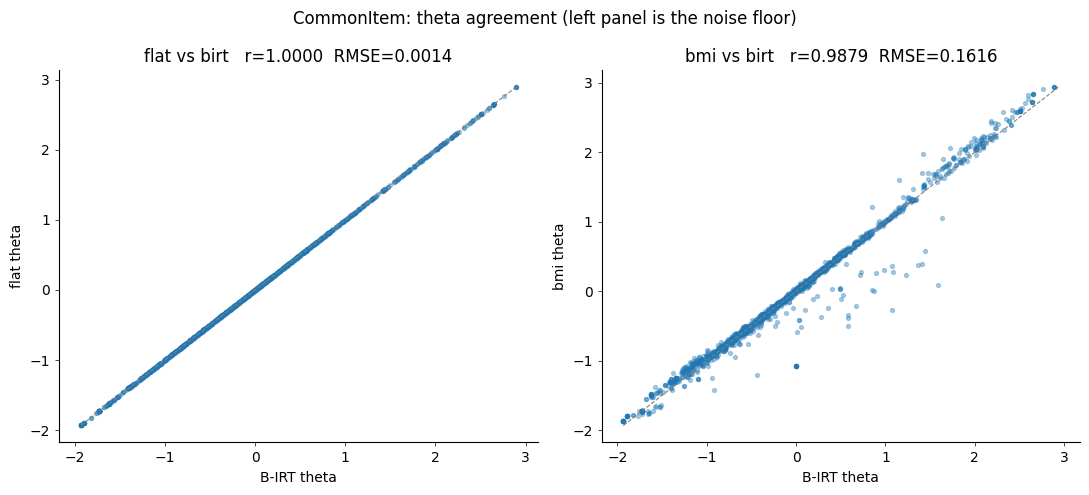

In [8]:
def _tufte(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.5)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, other in zip(axes, ["flat", "bmi"]):
    x, y = birt["eap"], results[other]["eap"]
    r = float(np.corrcoef(x, y)[0, 1])
    rmse = float(np.sqrt(np.mean((x - y) ** 2)))
    ax.scatter(x, y, s=8, alpha=0.35)
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
    ax.plot([lo, hi], [lo, hi], color="gray", lw=0.8, ls="--")
    ax.set_xlabel("B-IRT theta")
    ax.set_ylabel(f"{other} theta")
    ax.set_title(f"{other} vs birt   r={r:.4f}  RMSE={rmse:.4f}")
    _tufte(ax)
fig.suptitle(f"{DESIGN}: theta agreement (left panel is the noise floor)")
fig.tight_layout()

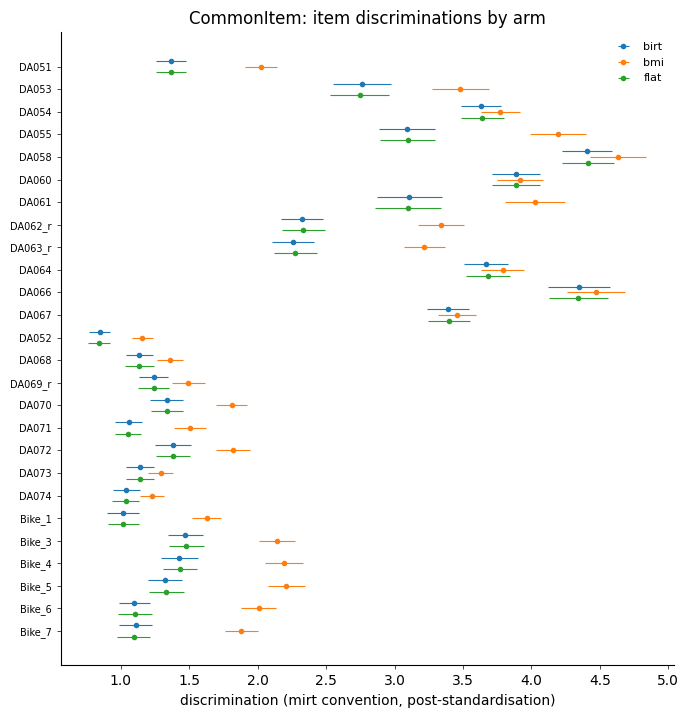

In [9]:
# Discriminations, with the flat/birt gap as the reference for "no difference".
fig, ax = plt.subplots(figsize=(7, max(4, len(ITEM_KEYS) * 0.28)))
y = np.arange(len(ITEM_KEYS))
for off, (name, res) in zip([-0.25, 0.0, 0.25], results.items()):
    ip = res["item_params"]
    ax.errorbar(ip["a_mean"], y + off, xerr=ip["a_sd"], fmt="o", ms=3,
                lw=0.8, capsize=0, label=name)
ax.set_yticks(y)
ax.set_yticklabels(ITEM_KEYS, fontsize=7)
ax.invert_yaxis()
ax.set_xlabel("discrimination (mirt convention, post-standardisation)")
ax.legend(frameon=False, fontsize=8)
ax.set_title(f"{DESIGN}: item discriminations by arm")
_tufte(ax)
fig.tight_layout()

## Outputs

`fit_arm` already wrote `{birt,bmi,flat}.npz` and `_report_noise_floor`
wrote `noise_floor.json`, both under `OUTPUT_DIR`. The cell below adds a
single combined file for the cross-design comparison.

Item parameters are stored in mirt's convention (`d_ik = -a_i * b_ik`), with
thresholds already `cumsum`-ed from the stored increments and extracted
*after* `standardize_marginal`. Do not redo any of those three steps
downstream — `to_mirt_convention` centralises them.

In [10]:
np.savez(
    OUTPUT_DIR / "summary.npz",
    design=np.asarray(DESIGN),
    item_keys=np.asarray(ITEM_KEYS),
    form=df[FORM_KEY].to_numpy() if FORM_KEY in df.columns else np.asarray([]),
    smoke=np.asarray(SMOKE),
    **{f"{n}_{k}": np.asarray(res[k])
       for n, res in results.items() for k in ("eap", "psd", "max_rhat")},
    **{f"{n}_a_mean": res["item_params"]["a_mean"] for n, res in results.items()},
    **{f"{n}_d_mean": res["item_params"]["d_mean"] for n, res in results.items()},
)
print(f"wrote {OUTPUT_DIR / 'summary.npz'}")

wrote /home/luis/CGE/mice_imp/results/commonitem/summary.npz
